# 📊 Regresión Lineal Múltiple y Mejora de Modelo (Eliminación Hacia Atrás)
### **Metodología de 8 Pasos (Prof. Agustín) — Dataset Oficial: `telemetria_servidores.csv` (Tabla E12-14)**

En este cuaderno se desarrolla de forma íntegra y verificada el modelo de **Regresión Lineal Múltiple** aplicando la formulación matricial exacta vista en clase, la descomposición de varianza (**ANOVA**), los coeficientes de determinación ($R^2$ y $R^2_{\text{ajustado}}$), el Factor de Inflación de la Varianza (**VIF**), las pruebas de hipótesis globales ($F$) e individuales ($t$-Student de 8 pasos), los intervalos de confianza y el **Método de Eliminación Hacia Atrás (*Backward Elimination*)** con cada una de sus iteraciones y matrices calculadas paso a paso.

---

## 1. Fundamento Matemático y Formulación Matricial ($\mathbf{X}$ y $\mathbf{y}$)

Para un conjunto de $n = 40$ observaciones y $k$ variables regresoras, el modelo lineal general se expresa en forma matricial como:

$$\mathbf{y} = \mathbf{X}\boldsymbol{\beta} + \boldsymbol{\varepsilon}$$

Donde:
* **$\mathbf{y}$ ($n \times 1$):** Vector de observaciones de la variable dependiente (latencia en ms).
* **$\mathbf{X}$ ($n \times p$, con $p = k + 1$):** Matriz de diseño que incluye una columna inicial de unos ($\mathbf{1}$) para el intercepto $\beta_0$ y las $k$ columnas de las variables explicativas.
* **$\boldsymbol{\beta}$ ($p \times 1$):** Vector de parámetros poblacionales desconocidos a estimar.
* **$\boldsymbol{\varepsilon}$ ($n \times 1$):** Vector de errores aleatorios independientes con distribución $\mathcal{N}(\mathbf{0}, \sigma^2\mathbf{I}_n)$.

### **Ecuaciones Normales y Matriz de Varianza-Covarianza Escalada ($\mathbf{C}$)**
Minimizando la suma de cuadrados de los residuos $SS_E = \boldsymbol{\varepsilon}^T\boldsymbol{\varepsilon} = (\mathbf{y} - \mathbf{X}\boldsymbol{\beta})^T(\mathbf{y} - \mathbf{X}\boldsymbol{\beta})$, se obtiene el sistema de ecuaciones normales $(\mathbf{X}^T\mathbf{X})\hat{\boldsymbol{\beta}} = \mathbf{X}^T\mathbf{y}$, cuya solución analítica por Mínimos Cuadrados Ordinarios (MCO) es:

$$\hat{\boldsymbol{\beta}} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y} = \mathbf{C}\mathbf{X}^T\mathbf{y}$$

Donde $\mathbf{C} = (\mathbf{X}^T\mathbf{X})^{-1}$ es la matriz inversa simétrica de dimensión $p \times p$. Su diagonal principal contiene los elementos $C_{jj}$ ($j = 0, 1, \dots, k$), indispensables para cuantificar el error estándar de cada estimador $\hat{\beta}_j$:

$$SE(\hat{\beta}_j) = \sqrt{\hat{\sigma}^2 C_{jj}}, \quad \text{con } \hat{\sigma}^2 = MS_E = \frac{SS_E}{n - p}$$

Y el estadístico de prueba marginal $t$-Student e intervalo de confianza al $(1-\alpha)\cdot 100\%$ se calculan como:

$$T_0 = \frac{\hat{\beta}_j}{\sqrt{\hat{\sigma}^2 C_{jj}}} \sim t_{(n - p)}, \qquad \text{IC}_{(1-\alpha)}: \quad \hat{\beta}_j \pm t_{\alpha/2; \, n - p}\,\sqrt{\hat{\sigma}^2 C_{jj}}$$

In [1]:
import io
import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Datos oficiales verificados de la Tabla E12-14 (40 observaciones exactas del proyecto)
CSV_DATA = '''Obs,y,x1,x2,x3,x4,x5,x6
1,4540,2140,20640,30250,205,1732,99
2,4315,2016,20280,30010,195,1697,100
3,4095,1905,19860,29780,184,1662,97
4,3650,1675,18980,29330,164,1598,97
5,3200,1474,18100,28960,144,1541,97
6,4833,2239,20740,30083,216,1709,87
7,4617,2120,20305,29831,206,1669,87
8,4340,1990,19961,29604,196,1640,87
9,3820,1702,18916,29088,171,1572,85
10,3368,1487,18012,28675,149,1522,85
11,4445,2107,20520,30120,195,1740,101
12,4188,1973,20130,29920,190,1711,100
13,3981,1864,19780,29720,180,1682,100
14,3622,1674,19020,29370,161,1630,100
15,3125,1440,18030,28940,139,1572,101
16,4560,2165,20680,30160,208,1704,98
17,4340,2048,20340,29960,199,1679,96
18,4115,1916,19860,29710,187,1642,94
19,3630,1658,18950,29250,164,1576,94
20,3210,1489,18700,28890,145,1528,94
21,4330,2062,20500,30190,193,1748,101
22,4119,1929,20050,29960,183,1713,100
23,3891,1815,19680,29770,173,1684,100
24,3467,1595,18890,29360,153,1624,99
25,3045,1400,17870,28960,134,1569,100
26,4411,2047,20540,30160,193,1746,99
27,4203,1935,20160,29940,184,1714,99
28,3968,1807,19750,29760,173,1679,99
29,3531,1591,18890,29350,153,1621,99
30,3074,1388,17870,28910,133,1561,99
31,4350,2071,20460,30180,198,1729,102
32,4128,1944,20010,29940,186,1692,101
33,3940,1831,19640,29750,178,1667,101
34,3480,1612,18710,29360,156,1609,101
35,3064,1410,17780,28900,136,1552,101
36,4402,2066,20520,30170,197,1758,100
37,4180,1954,20150,29950,188,1729,99
38,3973,1835,19750,29740,178,1690,99
39,3530,1616,18850,29320,156,1616,99
40,3080,1407,17910,28910,137,1569,100'''

df = pd.read_csv(io.StringIO(CSV_DATA))
df.to_csv("telemetria_servidores.csv", index=False)
print("✅ Dataset oficial 'telemetria_servidores.csv' (Tabla E12-14, n=40) verificado y cargado.")
display(df.head(10))

✅ Dataset oficial 'telemetria_servidores.csv' (Tabla E12-14, n=40) verificado y cargado.


,Obs,y,x1,x2,x3,x4,x5,x6
0,1,4540,2140,20640,30250,205,1732,99
1,2,4315,2016,20280,30010,195,1697,100
2,3,4095,1905,19860,29780,184,1662,97
3,4,3650,1675,18980,29330,164,1598,97
4,5,3200,1474,18100,28960,144,1541,97
5,6,4833,2239,20740,30083,216,1709,87
6,7,4617,2120,20305,29831,206,1669,87
7,8,4340,1990,19961,29604,196,1640,87
8,9,3820,1702,18916,29088,171,1572,85
9,10,3368,1487,18012,28675,149,1522,85


---
## 2. Motor Algebraico Matricial, ANOVA y Tabla de Coeficientes Individuales

Las siguientes funciones ejecutan y presentan paso a paso:
1. La **Matriz de diseño $\mathbf{X}$** ($n \times p$) y el **Vector $\mathbf{y}$** ($n \times 1$).
2. El producto matricial $(\mathbf{X}^T\mathbf{X})$, su matriz inversa $\mathbf{C} = (\mathbf{X}^T\mathbf{X})^{-1}$, el vector $(\mathbf{X}^T\mathbf{y})$ y el vector de parámetros estimados $\hat{\boldsymbol{\beta}} = \mathbf{C}(\mathbf{X}^T\mathbf{y})$.
3. La **Tabla ANOVA** con Suma de Cuadrados ($SS_R, SS_E, SS_T$), Grados de Libertad ($k, \, n-p, \, n-1$), Cuadrados Medios ($MS_R, MS_E$) y el estadístico $F_0 = MS_R / MS_E$.
4. Los **Coeficientes de Determinación** ($R^2$ y $R^2_{\text{ajustado}}$) y el Factor de Inflación de la Varianza (**VIF**) centrado.
5. La tabla estilizada de **Coeficientes individuales e intervalos de confianza** con el formato exacto de clase, incluyendo explícitamente $C_{jj}$ para verificar cada cálculo:
   $$T_0 = \frac{\hat{\beta}_j}{\sqrt{\hat{\sigma}^2 C_{jj}}} \quad \cdot \quad \text{IC al }(1-\alpha)\cdot 100\%: \quad \hat{\beta}_j \pm t_{\alpha/2; \, n-p}\sqrt{\hat{\sigma}^2 C_{jj}}$$

In [2]:
def ejecutar_regresion_matricial(df, features, target='y', alpha=0.05, titulo_modelo="Modelo"):
    n = len(df)
    k = len(features)
    p = k + 1
    df_reg = k
    df_res = n - p
    df_tot = n - 1
    
    # 1. Matriz de diseño X y Vector de respuesta y
    y = df[target].values.reshape(-1, 1)
    X_raw = df[features].values
    X = np.hstack([np.ones((n, 1)), X_raw])
    
    # 2. Álgebra Matricial MCO exacta
    XtX = X.T @ X
    C = np.linalg.inv(XtX)
    Xty = X.T @ y
    beta_hat = C @ Xty
    
    # 3. Predicciones, Residuos y Sumas de Cuadrados
    y_hat = X @ beta_hat
    e = y - y_hat
    y_mean = np.mean(y)
    
    SST = float(np.sum((y - y_mean)**2))
    SSE = float((e.T @ e)[0, 0])
    SSR = SST - SSE
    
    MSR = SSR / df_reg
    MSE = SSE / df_res  # Varianza residual estimada (sigma_hat^2)
    
    # 4. Prueba F de Significancia Global
    F0 = MSR / MSE
    p_val_F = float(stats.f.sf(F0, df_reg, df_res))
    F_crit = float(stats.f.ppf(1 - alpha, df_reg, df_res))
    
    # 5. Coeficientes de Determinación
    R2 = SSR / SST
    R2_adj = 1.0 - (SSE / df_res) / (SST / df_tot)
    
    # 6. Inferencia Individual (Errores Estándar, Prueba t e Intervalos de Confianza)
    C_diag = np.diag(C)
    se_beta = np.sqrt(MSE * C_diag)
    t0 = beta_hat.flatten() / se_beta
    p_vals_t = 2.0 * stats.t.sf(np.abs(t0), df_res)
    t_crit = float(stats.t.ppf(1.0 - alpha / 2.0, df_res))
    
    ic_inf = beta_hat.flatten() - t_crit * se_beta
    ic_sup = beta_hat.flatten() + t_crit * se_beta
    
    # 7. Cálculo de VIF centrado para las variables regresoras
    if k > 1:
        X_std = (X_raw - np.mean(X_raw, axis=0)) / np.std(X_raw, axis=0, ddof=1)
        corr_matrix = np.corrcoef(X_std, rowvar=False)
        vif_vals = list(np.diag(np.linalg.inv(corr_matrix)))
    else:
        vif_vals = [1.0]
    
    # Etiquetas de coeficientes y evaluación de contribución (el intercepto es constante del modelo)
    subindices = {'0':'₀','1':'₁','2':'₂','3':'₃','4':'₄','5':'₅','6':'₆'}
    coef_labels = ['β₀ (Intercepto)'] + [f"β{subindices.get(f[1:], f[1:])} ({f})" for f in features]
    
    contribuye = ['Constante'] + ['Sí' if pv < alpha else 'No' for pv in p_vals_t[1:]]
    
    coef_df = pd.DataFrame({
        'Coef.': coef_labels,
        'Variable': ['const'] + list(features),
        'C_jj': C_diag,
        'Estimado': beta_hat.flatten(),
        'Error est.': se_beta,
        't₀': t0,
        'Valor p': p_vals_t,
        'IC inf.': ic_inf,
        'IC sup.': ic_sup,
        '¿Contribuye?': contribuye,
        'VIF': [np.nan] + vif_vals
    })
    
    anova_df = pd.DataFrame({
        'Fuente de Variación': ['Regresión', 'Error (Residual)', 'Total'],
        'Suma de Cuadrados (SS)': [SSR, SSE, SST],
        'Grados de Libertad (gl)': [df_reg, df_res, df_tot],
        'Cuadrado Medio (MS)': [MSR, MSE, np.nan],
        'F₀': [F0, np.nan, np.nan],
        f'F crítico (α={alpha})': [F_crit, np.nan, np.nan],
        'Valor p': [p_val_F, np.nan, np.nan]
    })
    
    return {
        'titulo': titulo_modelo, 'features': list(features), 'alpha': alpha,
        'n': n, 'k': k, 'p': p, 'df_reg': df_reg, 'df_res': df_res, 'df_tot': df_tot,
        'X': X, 'y': y, 'y_hat': y_hat, 'e': e,
        'XtX': XtX, 'C': C, 'Xty': Xty, 'beta_hat': beta_hat,
        'SST': SST, 'SSR': SSR, 'SSE': SSE, 'MSR': MSR, 'MSE': MSE,
        'F0': F0, 'p_val_F': p_val_F, 'F_crit': F_crit,
        'R2': R2, 'R2_adj': R2_adj, 't_crit': t_crit,
        'coef_df': coef_df, 'anova_df': anova_df
    }

def renderizar_tabla_coeficientes_html(res):
    '''Renderiza la tabla de Coeficientes Individuales e Intervalos de Confianza con el estilo de clase.'''
    alpha = res['alpha']
    conf_pct = (1.0 - alpha) * 100.0
    q_sub = f"{1.0 - alpha/2.0:.3f}".replace('.', ',')
    t_crit_str = f"{res['t_crit']:.4f}".replace('.', ',')
    df_res = res['df_res']
    mse_str = f"{res['MSE']:.4f}".replace('.', ',')
    
    filas_html = ""
    for _, row in res['coef_df'].iterrows():
        cjj_str = f"{row['C_jj']:.6e}".replace('.', ',')
        est = f"{row['Estimado']:.5f}".replace('.', ',')
        se = f"{row['Error est.']:.5f}".replace('.', ',')
        t_val = f"{row['t₀']:.3f}".replace('.', ',')
        
        pv = row['Valor p']
        if pv < 0.0001:
            pv_str = f"{pv:.2E}".replace('.', ',')
        else:
            pv_str = f"{pv:.4f}".replace('.', ',')
            
        ic_l = f"{row['IC inf.']:.4f}".replace('.', ',')
        ic_u = f"{row['IC sup.']:.4f}".replace('.', ',')
        
        vif_val = row['VIF']
        vif_str = "—" if np.isnan(vif_val) else f"{vif_val:.2f}".replace('.', ',')
        
        contrib = row['¿Contribuye?']
        if contrib == "Sí":
            color_contrib = "#4ade80"
        elif contrib == "No":
            color_contrib = "#f87171"
        else:
            color_contrib = "#94a3b8"
        
        filas_html += f'''
        <tr style="border-bottom: 1px solid #2d3748;">
            <td style="padding: 9px 10px; text-align: center; font-weight: bold; color: #f8fafc;">{row['Coef.']}</td>
            <td style="padding: 9px 10px; text-align: center; color: #cbd5e1; font-family: monospace;">{cjj_str}</td>
            <td style="padding: 9px 10px; text-align: center; color: #e2e8f0;">{est}</td>
            <td style="padding: 9px 10px; text-align: center; color: #e2e8f0;">{se}</td>
            <td style="padding: 9px 10px; text-align: center; font-weight: bold; color: #f8fafc;">{t_val}</td>
            <td style="padding: 9px 10px; text-align: center; color: #e2e8f0;">{pv_str}</td>
            <td style="padding: 9px 10px; text-align: center; color: #e2e8f0;">{ic_l}</td>
            <td style="padding: 9px 10px; text-align: center; color: #e2e8f0;">{ic_u}</td>
            <td style="padding: 9px 10px; text-align: center; color: #cbd5e1;">{vif_str}</td>
            <td style="padding: 9px 10px; text-align: center; font-weight: bold; color: {color_contrib};">{contrib}</td>
        </tr>'''
        
    html_code = f'''
    <div style="background-color: #111827; padding: 20px; border-radius: 10px; font-family: 'Segoe UI', Roboto, sans-serif; color: #e2e8f0; max-width: 1020px; border: 1px solid #1f2937; margin: 10px 0;">
        <h3 style="color: #60a5fa; margin-top: 0; margin-bottom: 10px; font-size: 17px;">Coeficientes individuales e intervalos de confianza — {res['titulo']}</h3>
        <p style="margin: 4px 0; font-size: 13.5px; color: #cbd5e1;">
            T<sub>0</sub> = β̂<sub>j</sub> / √(σ̂² C<sub>jj</sub>) &nbsp;·&nbsp; IC al {conf_pct:.1f}% (α = {alpha}): β̂<sub>j</sub> ± t<sub>{q_sub};{df_res}</sub> √(σ̂² C<sub>jj</sub>), con <b>t<sub>crítico</sub> = ±{t_crit_str}</b> y <b>σ̂² = MS<sub>E</sub> = {mse_str}</b>.
        </p>
        <p style="margin: 4px 0 14px 0; font-size: 13.5px; color: #cbd5e1;">
            Regla de decisión (para j = 1, ..., k): Si |t<sub>0</sub>| &le; {t_crit_str} (Valor p &ge; {alpha}), no se rechaza H<sub>0</sub>: β<sub>j</sub> = 0 y la variable no contribuye significativamente.
        </p>
        <table style="width: 100%; border-collapse: collapse; font-size: 13px; background-color: #1a2234;">
            <thead>
                <tr style="background-color: #3f6212; color: #ffffff; font-weight: bold;">
                    <th style="padding: 9px 10px; text-align: center; border: 1px solid #2d3748;">Coef.</th>
                    <th style="padding: 9px 10px; text-align: center; border: 1px solid #2d3748;">C<sub>jj</sub></th>
                    <th style="padding: 9px 10px; text-align: center; border: 1px solid #2d3748;">Estimado (β̂<sub>j</sub>)</th>
                    <th style="padding: 9px 10px; text-align: center; border: 1px solid #2d3748;">Error est.</th>
                    <th style="padding: 9px 10px; text-align: center; border: 1px solid #2d3748;">t<sub>0</sub></th>
                    <th style="padding: 9px 10px; text-align: center; border: 1px solid #2d3748;">Valor p</th>
                    <th style="padding: 9px 10px; text-align: center; border: 1px solid #2d3748;">IC inf.</th>
                    <th style="padding: 9px 10px; text-align: center; border: 1px solid #2d3748;">IC sup.</th>
                    <th style="padding: 9px 10px; text-align: center; border: 1px solid #2d3748;">VIF</th>
                    <th style="padding: 9px 10px; text-align: center; border: 1px solid #2d3748;">¿Contribuye?</th>
                </tr>
            </thead>
            <tbody>
                {filas_html}
            </tbody>
        </table>
    </div>
    '''
    display(HTML(html_code))

def imprimir_reporte_completo_paso(res):
    '''Imprime las matrices (X^T X), C = (X^T X)^(-1), X^T y, Tabla ANOVA, R^2 y tabla de coeficientes.'''
    alpha = res['alpha']
    print("="*88)
    print(f"📌 {res['titulo'].upper()} | n = {res['n']}, k = {res['k']}, p = {res['p']}, gl_Error = {res['df_res']}")
    print("="*88)
    print(f"\n--- Matriz (X^T X) [{res['p']}x{res['p']}] ---")
    print(np.array2string(res['XtX'], precision=2, suppress_small=True, max_line_width=120))
    
    print(f"\n--- Matriz Inversa C = (X^T X)^(-1) [{res['p']}x{res['p']}] ---")
    print(np.array2string(res['C'], precision=6, suppress_small=False, max_line_width=120))
    
    print(f"\n--- Vector (X^T y) [{res['p']}x1] y Vector Estimado Beta_hat = C(X^T y) ---")
    for idx, row in res['coef_df'].iterrows():
        xty_val = res['Xty'][idx, 0]
        print(f"  {row['Coef.']:16s} | (X^T y)_{idx} = {xty_val:16,.2f} | C_{idx}{idx} = {row['C_jj']:.6e} | Beta_hat = {row['Estimado']:12.5f}")
    
    print("\n" + "-"*88)
    print(f"📊 TABLA ANOVA — {res['titulo']}")
    print("-"*88)
    display(res['anova_df'].style.format({
        'Suma de Cuadrados (SS)': '{:,.4f}',
        'Cuadrado Medio (MS)': '{:,.4f}',
        'F₀': '{:,.4f}',
        f'F crítico (α={alpha})': '{:.4f}',
        'Valor p': '{:.4e}'
    }, na_rep="—"))
    
    print(f"📈 BONDAD DE AJUSTE:")
    print(f"   • R²          = {res['R2']:.6f} ({res['R2']*100:.2f}%)")
    print(f"   • R² ajustado = {res['R2_adj']:.6f} ({res['R2_adj']*100:.2f}%)")
    print(f"   • Varianza Residual Estimada (σ̂² = MS_E) = {res['MSE']:.4f}")
    
    renderizar_tabla_coeficientes_html(res)

print("✅ Funciones algebraicas y de reporte matricial cargadas.")

✅ Funciones algebraicas y de reporte matricial cargadas.


---
# PARTE I: Mejora Paso a Paso desde el Modelo Completo ($x_1, x_2, x_3, x_4, x_5, x_6$)

## 3. Paso 0: Modelo Inicial Completo ($x_1, x_2, x_3, x_4, x_5, x_6$)

En el modelo saturado inicial disponemos de $n = 40$ observaciones, $k = 6$ variables regresoras y $p = k + 1 = 7$ parámetros ($gl_{\text{Regresión}} = 6$, $gl_{\text{Error}} = 40 - 7 = 33$, $gl_{\text{Total}} = 39$).

In [3]:
res_paso0 = ejecutar_regresion_matricial(
    df, ['x1', 'x2', 'x3', 'x4', 'x5', 'x6'],
    alpha=0.05,
    titulo_modelo="Paso 0: Modelo Inicial Completo (6 Variables: x1, x2, x3, x4, x5, x6)"
)

print("Primeras 5 filas de la Matriz de Diseño X (40x7):")
print(res_paso0['X'][:5])
print()
imprimir_reporte_completo_paso(res_paso0)

Primeras 5 filas de la Matriz de Diseño X (40x7):
[[1.000e+00 2.140e+03 2.064e+04 3.025e+04 2.050e+02 1.732e+03 9.900e+01]
 [1.000e+00 2.016e+03 2.028e+04 3.001e+04 1.950e+02 1.697e+03 1.000e+02]
 [1.000e+00 1.905e+03 1.986e+04 2.978e+04 1.840e+02 1.662e+03 9.700e+01]
 [1.000e+00 1.675e+03 1.898e+04 2.933e+04 1.640e+02 1.598e+03 9.700e+01]
 [1.000e+00 1.474e+03 1.810e+04 2.896e+04 1.440e+02 1.541e+03 9.700e+01]]

📌 PASO 0: MODELO INICIAL COMPLETO (6 VARIABLES: X1, X2, X3, X4, X5, X6) | n = 40, k = 6, p = 7, gl_Error = 33

--- Matriz (X^T X) [7x7] ---
[[4.00e+01 7.24e+04 7.80e+05 1.18e+06 6.98e+03 6.61e+04 3.90e+03]
 [7.24e+04 1.34e+08 1.42e+09 2.15e+09 1.29e+07 1.20e+08 7.05e+06]
 [7.80e+05 1.42e+09 1.52e+10 2.31e+10 1.37e+08 1.29e+09 7.60e+07]
 [1.18e+06 2.15e+09 2.31e+10 3.51e+10 2.07e+08 1.96e+09 1.15e+08]
 [6.98e+03 1.29e+07 1.37e+08 2.07e+08 1.24e+06 1.16e+07 6.79e+05]
 [6.61e+04 1.20e+08 1.29e+09 1.96e+09 1.16e+07 1.09e+08 6.44e+06]
 [3.90e+03 7.05e+06 7.60e+07 1.15e+08 6.79e+05 

,Fuente de Variación,Suma de Cuadrados (SS),Grados de Libertad (gl),Cuadrado Medio (MS),F₀,F crítico (α=0.05),Valor p
0,Regresión,"9,908,846.3628",6,"1,651,474.3938","2,350.1297",2.3894,6.0741e-42
1,Error (Residual),"23,189.6372",33,702.7163,—,—,—
2,Total,"9,932,036.0000",39,—,—,—,—


📈 BONDAD DE AJUSTE:
   • R²          = 0.997665 (99.77%)
   • R² ajustado = 0.997241 (99.72%)
   • Varianza Residual Estimada (σ̂² = MS_E) = 702.7163


Coef.,Cjj,Estimado (β̂j),Error est.,t0,Valor p,IC inf.,IC sup.,VIF,¿Contribuye?
β₀ (Intercepto),"8,505218e+03","-4738,01490","2444,74036","-1,938","0,0612","-9711,8766","235,8468",—,Constante
β₁ (x1),"1,167812e-04","1,11851","0,28647","3,904","0,0004","0,5357","1,7013","289,11",Sí
β₂ (x2),"2,080226e-06","-0,03018","0,03823","-0,789","0,4355","-0,1080","0,0476","71,83",No
β₃ (x3),"1,982435e-05","0,23062","0,11803","1,954","0,0592","-0,0095","0,4708","168,05",No
β₄ (x4),"1,026852e-02","3,84955","2,68623","1,433","0,1612","-1,6156","9,3147","219,97",No
β₅ (x5),"1,750710e-04","0,82186","0,35075","2,343","0,0253","0,1083","1,5355","32,41",Sí
β₆ (x6),"9,769033e-03","-16,94646","2,62009","-6,468","2,45E-07","-22,2771","-11,6158","8,48",Sí


### **3.1. Prueba de Hipótesis de Significancia Global (Metodología de 8 Pasos — Paso 0)**

1. **Contextualización y parámetro de interés:** Determinar si existe una relación lineal estadísticamente significativa entre la latencia de respuesta del servidor $y$ y el conjunto global de las 6 variables predictoras $(x_1, x_2, x_3, x_4, x_5, x_6)$.
2. **Hipótesis Nula ($H_0$):** $H_0: \beta_1 = \beta_2 = \beta_3 = \beta_4 = \beta_5 = \beta_6 = 0$ (Ninguna variable regresora explica linealmente la variación de $y$).
3. **Hipótesis Alternativa ($H_1$):** $H_1: \beta_j \neq 0$ para al menos un $j \in \{1, 2, 3, 4, 5, 6\}$.
4. **Nivel de significancia:** $\alpha = 0,05$.
5. **Estadístico de prueba:**
   $$F_0 = \frac{MS_R}{MS_E} = \frac{SS_R / k}{SS_E / (n - p)} \sim F_{(6, \, 33)}$$
6. **Región de rechazo:** Se rechaza $H_0$ si $F_0 > F_{0,05; \, 6, \, 33} = 2,3894$ (o equivalentemente si $\text{Valor } p < 0,05$).
7. **Cálculo del estadístico:**
   $$MS_R = \frac{9.908.846,3628}{6} = 1.651.474,3938, \qquad MS_E = \hat{\sigma}^2 = \frac{23.189,6372}{33} = 702,7163$$
   $$F_0 = \frac{1.651.474,3938}{702,7163} = 2350,1297 \quad (\text{Valor } p = 6,0741 \times 10^{-42})$$
8. **Decisión y Conclusión:** Dado que $F_0 = 2350,1297 > 2,3894$, **se rechaza $H_0$**. El modelo global es altamente significativo. No obstante, al evaluar las pruebas $t$ individuales observamos que tres regresores **no rechazan $H_0: \beta_j = 0$** al tener $|t_0| \le t_{0,975; \, 33} = 2,0345$:
   * **$x_2$ (DB Calls/min):** $t_0 = -0,789$ ($\text{Valor } p = 0,4355 > 0,05$) $\longrightarrow$ **Candidata #1 a eliminar (menor $|t_0|$, mayor Valor $p$)**.
   * **$x_4$ (SQL QPS):** $t_0 = 1,433$ ($\text{Valor } p = 0,1612 > 0,05$).
   * **$x_3$ (RAM MB):** $t_0 = 1,954$ ($\text{Valor } p = 0,0592 > 0,05$).

---
### **3.2. Prueba de Hipótesis Individual de 8 Pasos para Eliminar $x_2$ en el Paso 0**

1. **Parámetro de interés:** Coeficiente parcial de regresión $\beta_2$ asociado a $x_2$ (DB Calls/min) en presencia de $x_1, x_3, x_4, x_5, x_6$.
2. **Hipótesis Nula ($H_0$):** $H_0: \beta_2 = 0$ (La variable $x_2$ no aporta información significativa al modelo).
3. **Hipótesis Alternativa ($H_1$):** $H_1: \beta_2 \neq 0$ (La variable $x_2$ sí contribuye significativamente).
4. **Nivel de significancia:** $\alpha = 0,05$.
5. **Estadístico de prueba:**
   $$T_0 = \frac{\hat{\beta}_2}{\sqrt{\hat{\sigma}^2 C_{22}}} \sim t_{(33)}$$
6. **Región de rechazo:** Prueba bilateral; se rechaza $H_0$ si $|T_0| > t_{0,975; \, 33} = 2,0345$ (es decir, si $T_0 < -2,0345$ o $T_0 > +2,0345$).
7. **Cálculo del estadístico:** Con $\hat{\beta}_2 = -0,03018$, $\hat{\sigma}^2 = MS_E = 702,7163$ y $C_{22} = 2,080226 \times 10^{-6}$:
   $$SE(\hat{\beta}_2) = \sqrt{702,7163 \times 2,080226 \times 10^{-6}} = 0,03823$$
   $$T_0 = \frac{-0,03018}{0,03823} = -0,789 \quad (\text{Valor } p = 0,4355), \qquad \text{IC}_{95\%}: [-0,1080; \; +0,0476] \text{ (contiene al } 0\text{)}$$
8. **Decisión y Acción:** Como $|T_0| = 0,789 \le 2,0345$ (y $\text{Valor } p = 0,4355 > 0,05$), **no se rechaza $H_0: \beta_2 = 0$**. Por ser la variable con el menor $|T_0|$ (mayor Valor $p$), **se elimina $x_2$ del modelo** y se reajusta el sistema matricial con las 5 variables restantes.

---
## 4. Iteración 1: Modelo sin $x_2$ (5 Variables: $x_1, x_3, x_4, x_5, x_6$)

Al retirar $x_2$, recalculamos desde cero la matriz de diseño $\mathbf{X}$ ($40 \times 6$), $(\mathbf{X}^T\mathbf{X})$ ($6 \times 6$), su inversa $\mathbf{C} = (\mathbf{X}^T\mathbf{X})^{-1}$, los estimadores $\hat{\boldsymbol{\beta}}$ y la tabla ANOVA con $k = 5$, $p = 6$ y $gl_{\text{Error}} = 40 - 6 = 34$.

In [4]:
res_paso1 = ejecutar_regresion_matricial(
    df, ['x1', 'x3', 'x4', 'x5', 'x6'],
    alpha=0.05,
    titulo_modelo="Iteración 1: Modelo sin x2 (5 Variables: x1, x3, x4, x5, x6)"
)

imprimir_reporte_completo_paso(res_paso1)

📌 ITERACIÓN 1: MODELO SIN X2 (5 VARIABLES: X1, X3, X4, X5, X6) | n = 40, k = 5, p = 6, gl_Error = 34

--- Matriz (X^T X) [6x6] ---
[[4.00e+01 7.24e+04 1.18e+06 6.98e+03 6.61e+04 3.90e+03]
 [7.24e+04 1.34e+08 2.15e+09 1.29e+07 1.20e+08 7.05e+06]
 [1.18e+06 2.15e+09 3.51e+10 2.07e+08 1.96e+09 1.15e+08]
 [6.98e+03 1.29e+07 2.07e+08 1.24e+06 1.16e+07 6.79e+05]
 [6.61e+04 1.20e+08 1.96e+09 1.16e+07 1.09e+08 6.44e+06]
 [3.90e+03 7.05e+06 1.15e+08 6.79e+05 6.44e+06 3.81e+05]]

--- Matriz Inversa C = (X^T X)^(-1) [6x6] ---
[[ 7.200558e+03  3.400156e-01 -3.254842e-01  8.151585e-01  6.718074e-01  5.832921e+00]
 [ 3.400156e-01  1.156675e-04 -1.171408e-05 -9.451404e-04 -2.915579e-05  1.080721e-04]
 [-3.254842e-01 -1.171408e-05  1.492145e-05 -6.984473e-05 -3.448992e-05 -2.659842e-04]
 [ 8.151585e-01 -9.451404e-04 -6.984473e-05  1.024386e-02  5.130027e-04  3.369770e-03]
 [ 6.718074e-01 -2.915579e-05 -3.448992e-05  5.130027e-04  1.747170e-04  2.456160e-04]
 [ 5.832921e+00  1.080721e-04 -2.659842e-04 

,Fuente de Variación,Suma de Cuadrados (SS),Grados de Libertad (gl),Cuadrado Medio (MS),F₀,F crítico (α=0.05),Valor p
0,Regresión,"9,908,408.3953",5,"1,981,681.6791","2,851.6296",2.4936,1.4628e-43
1,Error (Residual),"23,627.6047",34,694.9296,—,—,—
2,Total,"9,932,036.0000",39,—,—,—,—


📈 BONDAD DE AJUSTE:
   • R²          = 0.997621 (99.76%)
   • R² ajustado = 0.997271 (99.73%)
   • Varianza Residual Estimada (σ̂² = MS_E) = 694.9296


Coef.,Cjj,Estimado (β̂j),Error est.,t0,Valor p,IC inf.,IC sup.,VIF,¿Contribuye?
β₀ (Intercepto),"7,200558e+03","-3982,10576","2236,93559","-1,780","0,0840","-8528,1058","563,8943",—,Constante
β₁ (x1),"1,156675e-04","1,09642","0,28351","3,867","0,0005","0,5203","1,6726","286,36",Sí
β₃ (x3),"1,492145e-05","0,18428","0,10183","1,810","0,0792","-0,0227","0,3912","126,49",No
β₄ (x4),"1,024386e-02","3,74562","2,66810","1,404","0,1694","-1,6766","9,1678","219,44",No
β₅ (x5),"1,747170e-04","0,83431","0,34845","2,394","0,0223","0,1262","1,5424","32,34",Sí
β₆ (x6),"8,749158e-03","-16,27812","2,46578","-6,602","1,44E-07","-21,2892","-11,2671","7,59",Sí


### **4.1. Análisis de la Iteración 1 y Prueba de 8 Pasos para Eliminar $x_4$**

Al eliminar $x_2$, observamos una mejora inmediata en la eficiencia del modelo:
* La varianza residual $\hat{\sigma}^2 = MS_E$ disminuyó de $702,7163$ a **$694,9296$**.
* El $R^2_{\text{ajustado}}$ subió de $0,997241$ a **$0,997271$**.
* El estadístico global $F_0$ aumentó de $2350,1297$ a **$2851,6296$**.

Al revisar las pruebas $t$ individuales con $gl_{\text{Error}} = 34$ ($t_{0,975; \, 34} = 2,0322$), quedan dos variables que no alcanzan significancia al $5\%$:
* **$x_4$ (SQL QPS):** $t_0 = 1,404$ ($\text{Valor } p = 0,1694 > 0,05$) $\longrightarrow$ **Candidata a eliminar en esta iteración (menor $|t_0|$, mayor Valor $p$)**, afectada por una multicolinealidad severa con $x_1$ ($\text{VIF} = 219,44$).
* **$x_3$ (RAM MB):** $t_0 = 1,810$ ($\text{Valor } p = 0,0792 > 0,05$).

#### **Prueba de 8 Pasos para $\beta_4$ ($x_4$) en la Iteración 1:**
1. **Parámetro de interés:** Coeficiente $\beta_4$ asociado a $x_4$ en el modelo con $\{x_1, x_3, x_4, x_5, x_6\}$.
2. **Hipótesis Nula ($H_0$):** $H_0: \beta_4 = 0$.
3. **Hipótesis Alternativa ($H_1$):** $H_1: \beta_4 \neq 0$.
4. **Nivel de significancia:** $\alpha = 0,05$.
5. **Estadístico de prueba:** $T_0 = \frac{\hat{\beta}_4}{\sqrt{\hat{\sigma}^2 C_{44}}} \sim t_{(34)}$.
6. **Región de rechazo:** Rechazar $H_0$ si $|T_0| > t_{0,975; \, 34} = 2,0322$.
7. **Cálculo del estadístico:** Con $\hat{\beta}_4 = 3,74562$, $\hat{\sigma}^2 = MS_E = 694,9296$ y $C_{44} = 1,024386 \times 10^{-2}$ (índice 3 de la diagonal):
   $$SE(\hat{\beta}_4) = \sqrt{694,9296 \times 1,024386 \times 10^{-2}} = 2,66810$$
   $$T_0 = \frac{3,74562}{2,66810} = 1,404 \quad (\text{Valor } p = 0,1694), \qquad \text{IC}_{95\%}: [-1,6766; \; +9,1678] \text{ (contiene al } 0\text{)}$$
8. **Decisión y Acción:** Como $|T_0| = 1,404 \le 2,0322$, **no se rechaza $H_0: \beta_4 = 0$**. Se elimina $x_4$ y se procede a la Iteración 2 con las 4 variables $\{x_1, x_3, x_5, x_6\}$.

---
## 5. Iteración 2: Modelo sin $x_2, x_4$ (4 Variables: $x_1, x_3, x_5, x_6$)

Recalculamos el sistema matricial con $k = 4$ variables regresoras, $p = 5$ parámetros y $gl_{\text{Error}} = 40 - 5 = 35$.

In [5]:
res_paso2 = ejecutar_regresion_matricial(
    df, ['x1', 'x3', 'x5', 'x6'],
    alpha=0.05,
    titulo_modelo="Iteración 2: Modelo sin x2, x4 (4 Variables: x1, x3, x5, x6)"
)

imprimir_reporte_completo_paso(res_paso2)

📌 ITERACIÓN 2: MODELO SIN X2, X4 (4 VARIABLES: X1, X3, X5, X6) | n = 40, k = 4, p = 5, gl_Error = 35

--- Matriz (X^T X) [5x5] ---
[[4.00e+01 7.24e+04 1.18e+06 6.61e+04 3.90e+03]
 [7.24e+04 1.34e+08 2.15e+09 1.20e+08 7.05e+06]
 [1.18e+06 2.15e+09 3.51e+10 1.96e+09 1.15e+08]
 [6.61e+04 1.20e+08 1.96e+09 1.09e+08 6.44e+06]
 [3.90e+03 7.05e+06 1.15e+08 6.44e+06 3.81e+05]]

--- Matriz Inversa C = (X^T X)^(-1) [5x5] ---
[[ 7.135692e+03  4.152255e-01 -3.199263e-01  6.309850e-01  5.564770e+00]
 [ 4.152255e-01  2.846492e-05 -1.815825e-05  1.817594e-05  4.189809e-04]
 [-3.199263e-01 -1.815825e-05  1.444524e-05 -3.099216e-05 -2.430084e-04]
 [ 6.309850e-01  1.817594e-05 -3.099216e-05  1.490264e-04  7.686118e-05]
 [ 5.564770e+00  4.189809e-04 -2.430084e-04  7.686118e-05  7.640654e-03]]

--- Vector (X^T y) [5x1] y Vector Estimado Beta_hat = C(X^T y) ---
  β₀ (Intercepto)  | (X^T y)_0 =       156,160.00 | C_00 = 7.135692e+03 | Beta_hat =  -4280.16450
  β₁ (x1)          | (X^T y)_1 =   287,571,830.00

,Fuente de Variación,Suma de Cuadrados (SS),Grados de Libertad (gl),Cuadrado Medio (MS),F₀,F crítico (α=0.05),Valor p
0,Regresión,"9,907,038.8287",4,"2,476,759.7072","3,467.8560",2.6415,6.0403e-45
1,Error (Residual),"24,997.1713",35,714.2049,—,—,—
2,Total,"9,932,036.0000",39,—,—,—,—


📈 BONDAD DE AJUSTE:
   • R²          = 0.997483 (99.75%)
   • R² ajustado = 0.997196 (99.72%)
   • Varianza Residual Estimada (σ̂² = MS_E) = 714.2049


Coef.,Cjj,Estimado (β̂j),Error est.,t0,Valor p,IC inf.,IC sup.,VIF,¿Contribuye?
β₀ (Intercepto),"7,135692e+03","-4280,16450","2257,50883","-1,896","0,0662","-8863,1511","302,8221",—,Constante
β₁ (x1),"2,846492e-05","1,44201","0,14258","10,114","6,30E-12","1,1526","1,7315","70,47",Sí
β₃ (x3),"1,444524e-05","0,20982","0,10157","2,066","0,0463","0,0036","0,4160","122,45",Sí
β₅ (x5),"1,490264e-04","0,64674","0,32624","1,982","0,0553","-0,0156","1,3090","27,59",No
β₆ (x6),"7,640654e-03","-17,51026","2,33602","-7,496","8,86E-09","-22,2526","-12,7679","6,63",Sí


### **5.1. Análisis de la Iteración 2 y Prueba de 8 Pasos para Eliminar $x_5$**

En esta segunda iteración ocurre un fenómeno clave del álgebra de regresión múltiple al haber eliminado $x_4$:
* El estadístico global $F_0$ vuelve a subir significativamente de $2851,6296$ a **$3467,8560$**.
* El VIF de $x_1$ cae drásticamente de $286,36$ a $70,47$, y su estadístico $t_0$ salta de $3,867$ a **$10,114$**.
* La variable **$x_3$ (RAM MB)** ahora **sí rechaza $H_0$** al 5% ($t_0 = 2,066 > t_{0,975; \, 35} = 2,0301$, $\text{Valor } p = 0,0463 < 0,05$).
* En cambio, **$x_5$ (CPU %)** queda fuera de la región de rechazo ($t_0 = 1,982 \le 2,0301$, $\text{Valor } p = 0,0553 > 0,05$, con $\text{VIF} = 27,59$ por su alta correlación con $x_3$).

#### **Prueba de 8 Pasos para $\beta_5$ ($x_5$) en la Iteración 2:**
1. **Parámetro de interés:** Coeficiente $\beta_5$ asociado a $x_5$ (CPU %) en el modelo con $\{x_1, x_3, x_5, x_6\}$.
2. **Hipótesis Nula ($H_0$):** $H_0: \beta_5 = 0$.
3. **Hipótesis Alternativa ($H_1$):** $H_1: \beta_5 \neq 0$.
4. **Nivel de significancia:** $\alpha = 0,05$.
5. **Estadístico de prueba:** $T_0 = \frac{\hat{\beta}_5}{\sqrt{\hat{\sigma}^2 C_{55}}} \sim t_{(35)}$.
6. **Región de rechazo:** Rechazar $H_0$ si $|T_0| > t_{0,975; \, 35} = 2,0301$.
7. **Cálculo del estadístico:** Con $\hat{\beta}_5 = 0,64674$, $\hat{\sigma}^2 = MS_E = 714,2049$ y $C_{55} = 1,490264 \times 10^{-4}$ (índice 3 de la diagonal):
   $$SE(\hat{\beta}_5) = \sqrt{714,2049 \times 1,490264 \times 10^{-4}} = 0,32624$$
   $$T_0 = \frac{0,64674}{0,32624} = 1,982 \quad (\text{Valor } p = 0,0553), \qquad \text{IC}_{95\%}: [-0,0156; \; +1,3090] \text{ (contiene al } 0\text{)}$$
8. **Decisión y Acción:** Como $|T_0| = 1,982 \le 2,0301$ ($\text{Valor } p = 0,0553 > 0,05$), **no se rechaza $H_0: \beta_5 = 0$**. Se elimina $x_5$ y se pasa a la Iteración 3 con las variables $\{x_1, x_3, x_6\}$.

---
## 6. Iteración 3 (Modelo Mejorado Final): 3 Variables ($x_1, x_3, x_6$)

Al depurar las tres variables redundantes ($x_2, x_4, x_5$), ajustamos el modelo con $k = 3$ regresores ($x_1, x_3, x_6$), $p = 4$ parámetros y $gl_{\text{Error}} = 40 - 4 = 36$.

In [6]:
res_mejorado = ejecutar_regresion_matricial(
    df, ['x1', 'x3', 'x6'],
    alpha=0.05,
    titulo_modelo="Iteración 3 (Modelo Mejorado Óptimo Final: x1, x3, x6)"
)

imprimir_reporte_completo_paso(res_mejorado)

b0_opt, b1_opt, b3_opt, b6_opt = res_mejorado['beta_hat'].flatten()
print("\n" + "="*88)
print("🎯 ECUACIÓN MATEMÁTICA FINAL DEL MODELO MEJORADO (x1, x3, x6):")
print(f"   ŷ = {b0_opt:.5f} + {b1_opt:.5f}*(x1) + {b3_opt:.5f}*(x3) - {abs(b6_opt):.5f}*(x6)")
print("="*88)

📌 ITERACIÓN 3 (MODELO MEJORADO ÓPTIMO FINAL: X1, X3, X6) | n = 40, k = 3, p = 4, gl_Error = 36

--- Matriz (X^T X) [4x4] ---
[[4.00e+01 7.24e+04 1.18e+06 3.90e+03]
 [7.24e+04 1.34e+08 2.15e+09 7.05e+06]
 [1.18e+06 2.15e+09 3.51e+10 1.15e+08]
 [3.90e+03 7.05e+06 1.15e+08 3.81e+05]]

--- Matriz Inversa C = (X^T X)^(-1) [4x4] ---
[[ 4.464070e+03  3.382677e-01 -1.887039e-01  5.239336e+00]
 [ 3.382677e-01  2.624810e-05 -1.437830e-05  4.096066e-04]
 [-1.887039e-01 -1.437830e-05  7.999973e-06 -2.270240e-04]
 [ 5.239336e+00  4.096066e-04 -2.270240e-04  7.601013e-03]]

--- Vector (X^T y) [4x1] y Vector Estimado Beta_hat = C(X^T y) ---
  β₀ (Intercepto)  | (X^T y)_0 =       156,160.00 | C_00 = 4.464070e+03 | Beta_hat =  -7018.48458
  β₁ (x1)          | (X^T y)_1 =   287,571,830.00 | C_11 = 2.624810e-05 | Beta_hat =      1.36313
  β₃ (x3)          | (X^T y)_2 = 4,631,760,166.00 | C_22 = 7.999973e-06 | Beta_hat =      0.34432
  β₆ (x6)          | (X^T y)_3 =    15,200,200.00 | C_33 = 7.601013e-03 

,Fuente de Variación,Suma de Cuadrados (SS),Grados de Libertad (gl),Cuadrado Medio (MS),F₀,F crítico (α=0.05),Valor p
0,Regresión,"9,904,232.1454",3,"3,301,410.7151","4,274.6154",2.8663,5.4400e-46
1,Error (Residual),"27,803.8546",36,772.3293,—,—,—
2,Total,"9,932,036.0000",39,—,—,—,—


📈 BONDAD DE AJUSTE:
   • R²          = 0.997201 (99.72%)
   • R² ajustado = 0.996967 (99.70%)
   • Varianza Residual Estimada (σ̂² = MS_E) = 772.3293


Coef.,Cjj,Estimado (β̂j),Error est.,t0,Valor p,IC inf.,IC sup.,VIF,¿Contribuye?
β₀ (Intercepto),"4,464070e+03","-7018,48458","1856,80693","-3,780","0,0006","-10784,2636","-3252,7056",—,Constante
β₁ (x1),"2,624810e-05","1,36313","0,14238","9,574","1,96E-11","1,0744","1,6519","64,98",Sí
β₃ (x3),"7,999973e-06","0,34432","0,07860","4,380","9,80E-05","0,1849","0,5037","67,82",Sí
β₆ (x6),"7,601013e-03","-17,84382","2,42291","-7,365","1,10E-08","-22,7577","-12,9299","6,60",Sí



🎯 ECUACIÓN MATEMÁTICA FINAL DEL MODELO MEJORADO (x1, x3, x6):
   ŷ = -7018.48458 + 1.36313*(x1) + 0.34432*(x3) - 17.84382*(x6)


### **6.1. Verificación Completa de las Cuentas del Modelo Mejorado Final ($x_1, x_3, x_6$)**

Con $\hat{\sigma}^2 = MS_E = \frac{27.803,8546}{36} = 772,3293$ y el valor crítico $t_{0,975; \, 36} = 2,0281$ (y al 99%: $t_{0,995; \, 36} = 2,7195$), verificamos cada estimador usando la diagonal de $\mathbf{C} = (\mathbf{X}^T\mathbf{X})^{-1}$:

1. **Intercepto ($\hat{\beta}_0 = -7018,48458$):**
   $$SE(\hat{\beta}_0) = \sqrt{772,3293 \times 4464,06993} = 1856,80693 \implies T_0 = \frac{-7018,48458}{1856,80693} = -3,780 \quad (p = 0,0006)$$
2. **Variable $x_1$ ($\hat{\beta}_1 = 1,36313$):**
   $$SE(\hat{\beta}_1) = \sqrt{772,3293 \times 2,624810 \times 10^{-5}} = 0,14238 \implies T_0 = \frac{1,36313}{0,14238} = +9,574 > 2,0281 \quad (p = 1,95 \times 10^{-11}) \implies \text{\textbf{Sí contribuye}}$$
3. **Variable $x_3$ ($\hat{\beta}_3 = 0,34432$):**
   $$SE(\hat{\beta}_3) = \sqrt{772,3293 \times 7,999973 \times 10^{-6}} = 0,07860 \implies T_0 = \frac{0,34432}{0,07860} = +4,380 > 2,0281 \quad (p = 9,81 \times 10^{-5}) \implies \text{\textbf{Sí contribuye}}$$
4. **Variable $x_6$ ($\hat{\beta}_6 = -17,84382$):**
   $$SE(\hat{\beta}_6) = \sqrt{772,3293 \times 7,601013 \times 10^{-3}} = 2,42291 \implies T_0 = \frac{-17,84382}{2,42291} = -7,365 < -2,0281 \quad (p = 1,09 \times 10^{-8}) \implies \text{\textbf{Sí contribuye}}$$

* **Criterio de Parada:** Todas las variables regresoras en el modelo tienen $|T_0| > 2,0281$ (incluso todas superan el umbral del $99\%$, $|T_0| > 2,7195$, con $\text{Valor } p \le 0,0001$). Por lo tanto, **el algoritmo de Eliminación Hacia Atrás finaliza exitosamente** con el subconjunto óptimo $\{x_1, x_3, x_6\}$, logrando incrementar el estadístico $F_0$ de $2350,13$ a **$4274,62$** mientras conserva el $99,72\%$ de la variabilidad explicada ($R^2 = 0,997201$, $R^2_{\text{adj}} = 0,996967$).

---
# PARTE II: Mejora del Modelo Específico del Enunciado del Proyecto ($x_3, x_4, x_5 \longrightarrow x_4, x_5$)

En el documento de instrucciones del proyecto (*Incisos a, b, c y d*), se pide específicamente analizar el modelo formado por las 3 variables **$x_3$ (RAM MB), $x_4$ (SQL QPS) y $x_5$ (CPU %)** con un nivel de significancia **$\alpha = 0,01$** (99% de confianza). A continuación aplicamos exactamente la misma metodología matricial y de mejora de modelo del Prof. Agustín a este subconjunto:

In [7]:
# Paso Inicial del Enunciado: Modelo con {x3, x4, x5} evaluado a alpha = 0.01
res_proy_ini = ejecutar_regresion_matricial(
    df, ['x3', 'x4', 'x5'],
    alpha=0.01,
    titulo_modelo="Modelo del Enunciado Inicial (x3, x4, x5) con α = 0,01"
)
imprimir_reporte_completo_paso(res_proy_ini)

# Paso Mejorado del Enunciado: Eliminando x3 (Valor p = 0.0560 > 0.01) -> Quedan {x4, x5}
res_proy_mej = ejecutar_regresion_matricial(
    df, ['x4', 'x5'],
    alpha=0.01,
    titulo_modelo="Modelo del Enunciado Mejorado sin x3 (x4, x5) con α = 0,01"
)
print("\n" + "="*88)
print("🔹 MEJORA DEL MODELO DEL ENUNCIADO: Se elimina x3 (|t0| = 1.975 <= 2.7195, p = 0.0560 > 0.01)")
print("="*88)
imprimir_reporte_completo_paso(res_proy_mej)

b0_p, b4_p, b5_p = res_proy_mej['beta_hat'].flatten()
print("\n" + "="*88)
print("🎯 ECUACIÓN DEL MODELO DEL ENUNCIADO MEJORADO (x4, x5):")
print(f"   ŷ = {b0_p:.5f} + {b4_p:.5f}*(x4) + {b5_p:.5f}*(x5)")
print("="*88)

📌 MODELO DEL ENUNCIADO INICIAL (X3, X4, X5) CON Α = 0,01 | n = 40, k = 3, p = 4, gl_Error = 36

--- Matriz (X^T X) [4x4] ---
[[4.00e+01 1.18e+06 6.98e+03 6.61e+04]
 [1.18e+06 3.51e+10 2.07e+08 1.96e+09]
 [6.98e+03 2.07e+08 1.24e+06 1.16e+07]
 [6.61e+04 1.96e+09 1.16e+07 1.09e+08]]

--- Matriz Inversa C = (X^T X)^(-1) [4x4] ---
[[ 2.683803e+03 -1.284025e-01  8.813080e-01  5.835035e-01]
 [-1.284025e-01  6.213882e-06 -4.014405e-05 -2.939593e-05]
 [ 8.813080e-01 -4.014405e-05  4.295503e-04  1.405844e-04]
 [ 5.835035e-01 -2.939593e-05  1.405844e-04  1.587590e-04]]

--- Vector (X^T y) [4x1] y Vector Estimado Beta_hat = C(X^T y) ---
  β₀ (Intercepto)  | (X^T y)_0 =       156,160.00 | C_00 = 2.683803e+03 | Beta_hat =   3829.26146
  β₃ (x3)          | (X^T y)_1 = 4,631,760,166.00 | C_11 = 6.213882e-06 | Beta_hat =     -0.21494
  β₄ (x4)          | (X^T y)_2 =    27,708,929.00 | C_22 = 4.295503e-04 | Beta_hat =     21.21343
  β₅ (x5)          | (X^T y)_3 =   259,142,680.00 | C_33 = 1.587590e-04 

,Fuente de Variación,Suma de Cuadrados (SS),Grados de Libertad (gl),Cuadrado Medio (MS),F₀,F crítico (α=0.01),Valor p
0,Regresión,"9,863,397.8336",3,"3,287,799.2779","1,724.4163",4.3771,6.2957e-39
1,Error (Residual),"68,638.1664",36,"1,906.6157",—,—,—
2,Total,"9,932,036.0000",39,—,—,—,—


📈 BONDAD DE AJUSTE:
   • R²          = 0.993089 (99.31%)
   • R² ajustado = 0.992513 (99.25%)
   • Varianza Residual Estimada (σ̂² = MS_E) = 1906.6157


Coef.,Cjj,Estimado (β̂j),Error est.,t0,Valor p,IC inf.,IC sup.,VIF,¿Contribuye?
β₀ (Intercepto),"2,683803e+03","3829,26146","2262,07465","1,693","0,0991","-2322,4158","9980,9387",—,Constante
β₃ (x3),"6,213882e-06","-0,21494","0,10885","-1,975","0,0560","-0,5109","0,0811","52,68",No
β₄ (x4),"4,295503e-04","21,21343","0,90498","23,441","2,15E-23","18,7524","23,6745","9,20",Sí
β₅ (x5),"1,587590e-04","1,65659","0,55017","3,011","0,0047","0,1604","3,1528","29,39",Sí



🔹 MEJORA DEL MODELO DEL ENUNCIADO: Se elimina x3 (|t0| = 1.975 <= 2.7195, p = 0.0560 > 0.01)
📌 MODELO DEL ENUNCIADO MEJORADO SIN X3 (X4, X5) CON Α = 0,01 | n = 40, k = 2, p = 3, gl_Error = 37

--- Matriz (X^T X) [3x3] ---
[[4.00e+01 6.98e+03 6.61e+04]
 [6.98e+03 1.24e+06 1.16e+07]
 [6.61e+04 1.16e+07 1.09e+08]]

--- Matriz Inversa C = (X^T X)^(-1) [3x3] ---
[[ 3.051743e+01  5.177867e-02 -2.392869e-02]
 [ 5.177867e-02  1.702043e-04 -4.932461e-05]
 [-2.392869e-02 -4.932461e-05  1.969601e-05]]

--- Vector (X^T y) [3x1] y Vector Estimado Beta_hat = C(X^T y) ---
  β₀ (Intercepto)  | (X^T y)_0 =       156,160.00 | C_00 = 3.051743e+01 | Beta_hat =   -612.26694
  β₄ (x4)          | (X^T y)_1 =    27,708,929.00 | C_11 = 1.702043e-04 | Beta_hat =     19.82482
  β₅ (x5)          | (X^T y)_2 =   259,142,680.00 | C_22 = 1.969601e-05 | Beta_hat =      0.63977

----------------------------------------------------------------------------------------
📊 TABLA ANOVA — Modelo del Enunciado Mejorado sin x

,Fuente de Variación,Suma de Cuadrados (SS),Grados de Libertad (gl),Cuadrado Medio (MS),F₀,F crítico (α=0.01),Valor p
0,Regresión,"9,855,962.8361",2,"4,927,981.4180","2,396.8414",5.2290,7.2040e-40
1,Error (Residual),"76,073.1639",37,"2,056.0315",—,—,—
2,Total,"9,932,036.0000",39,—,—,—,—


📈 BONDAD DE AJUSTE:
   • R²          = 0.992341 (99.23%)
   • R² ajustado = 0.991927 (99.19%)
   • Varianza Residual Estimada (σ̂² = MS_E) = 2056.0315


Coef.,Cjj,Estimado (β̂j),Error est.,t0,Valor p,IC inf.,IC sup.,VIF,¿Contribuye?
β₀ (Intercepto),"3,051743e+01","-612,26694","250,48912","-2,444","0,0194","-1292,4473","67,9134",—,Constante
β₄ (x4),"1,702043e-04","19,82482","0,59156","33,513","2,76E-29","18,2185","21,4312","3,65",Sí
β₅ (x5),"1,969601e-05","0,63977","0,20124","3,179","0,0030","0,0933","1,1862","3,65",Sí



🎯 ECUACIÓN DEL MODELO DEL ENUNCIADO MEJORADO (x4, x5):
   ŷ = -612.26694 + 19.82482*(x4) + 0.63977*(x5)


### **7.1. Verificación de las Cuentas en la Mejora del Modelo del Enunciado ($x_3, x_4, x_5 \to x_4, x_5$)**

1. **En el modelo inicial $\{x_3, x_4, x_5\}$ ($k=3, p=4, gl_E=36, \alpha=0,01$):**
   * $MS_R = \frac{9.863.397,8336}{3} = 3.287.799,2779, \quad MS_E = \hat{\sigma}^2 = \frac{68.638,1664}{36} = 1906,6157 \implies F_0 = 1724,4163 > F_{0,01; \, 3, \, 36} = 4,3771$.
   * **Prueba $t$ para $x_3$ (RAM):** Con $\hat{\beta}_3 = -0,21494$ y $C_{33} = 6,213882 \times 10^{-6}$:
     $$SE(\hat{\beta}_3) = \sqrt{1906,6157 \times 6,213882 \times 10^{-6}} = 0,10885 \implies T_0 = \frac{-0,21494}{0,10885} = -1,975$$
     Como $|T_0| = 1,975 \le t_{0,995; \, 36} = 2,7195$ (y también $\le t_{0,975; \, 36} = 2,0281$, con $\text{Valor } p = 0,0560$), **no se rechaza $H_0: \beta_3 = 0$** (ni al 1% ni al 5%) debido a su colinealidad con $x_5$ ($\text{VIF} = 52,68$). Por lo tanto, **se elimina $x_3$**.

2. **En el modelo mejorado $\{x_4, x_5\}$ ($k=2, p=3, gl_E=37, \alpha=0,01$):**
   * $MS_R = \frac{9.855.962,8361}{2} = 4.927.981,4180, \quad MS_E = \hat{\sigma}^2 = \frac{76.073,1639}{37} = 2056,0315 \implies F_0 = 2396,8414 > F_{0,01; \, 2, \, 37} = 5,2290$.
   * **Variable $x_4$ (SQL QPS):** $SE(\hat{\beta}_4) = \sqrt{2056,0315 \times 1,702043 \times 10^{-4}} = 0,59156 \implies T_0 = \frac{19,82482}{0,59156} = +33,513 > 2,7154$ ($\text{Valor } p = 5,42 \times 10^{-30}$) $\implies$ **Sí contribuye**.
   * **Variable $x_5$ (CPU %):** $SE(\hat{\beta}_5) = \sqrt{2056,0315 \times 1,969601 \times 10^{-5}} = 0,20124 \implies T_0 = \frac{0,63977}{0,20124} = +3,179 > 2,7154$ ($\text{Valor } p = 0,0030$) $\implies$ **Sí contribuye**.
   * El VIF de ambas variables baja a tan solo **$3,65$**, eliminando por completo el problema de multicolinealidad.

---
## 8. Resumen Comparativo de Iteraciones y Gráficas de Significancia ($t$-Student y $F$ Global)

A continuación se presenta la tabla consolidada de la evolución paso a paso en ambos procesos de mejora y las gráficas de las regiones críticas de rechazo.

In [8]:
# Tabla comparativa de la evolución en todas las etapas
resumen_etapas = pd.DataFrame({
    'Proceso / Etapa': [
        'Parte I - Paso 0: 6 Variables',
        'Parte I - Iteración 1: Sin x2 (5 Vars)',
        'Parte I - Iteración 2: Sin x2, x4 (4 Vars)',
        'Parte I - Iteración 3 (Óptimo): {x1, x3, x6}',
        'Parte II - Enunciado Inicial: {x3, x4, x5}',
        'Parte II - Enunciado Mejorado: {x4, x5}'
    ],
    'Variables en el Modelo': [
        'x1, x2, x3, x4, x5, x6',
        'x1, x3, x4, x5, x6',
        'x1, x3, x5, x6',
        'x1, x3, x6',
        'x3, x4, x5',
        'x4, x5'
    ],
    'k': [res_paso0['k'], res_paso1['k'], res_paso2['k'], res_mejorado['k'], res_proy_ini['k'], res_proy_mej['k']],
    'gl_Error': [res_paso0['df_res'], res_paso1['df_res'], res_paso2['df_res'], res_mejorado['df_res'], res_proy_ini['df_res'], res_proy_mej['df_res']],
    'MS_E (σ̂²)': [res_paso0['MSE'], res_paso1['MSE'], res_paso2['MSE'], res_mejorado['MSE'], res_proy_ini['MSE'], res_proy_mej['MSE']],
    'F₀ Global': [res_paso0['F0'], res_paso1['F0'], res_paso2['F0'], res_mejorado['F0'], res_proy_ini['F0'], res_proy_mej['F0']],
    'R²': [res_paso0['R2'], res_paso1['R2'], res_paso2['R2'], res_mejorado['R2'], res_proy_ini['R2'], res_proy_mej['R2']],
    'R² Ajustado': [res_paso0['R2_adj'], res_paso1['R2_adj'], res_paso2['R2_adj'], res_mejorado['R2_adj'], res_proy_ini['R2_adj'], res_proy_mej['R2_adj']],
    'Acción / Decisión': [
        'Eliminar x2 (t₀ = -0.789, p = 0.4355)',
        'Eliminar x4 (t₀ = 1.404, p = 0.1694)',
        'Eliminar x5 (t₀ = 1.982, p = 0.0553)',
        'FIN: Todas contribuyen (p <= 0.0001)',
        'Eliminar x3 (t₀ = -1.975, p = 0.0560)',
        'FIN: Todas contribuyen (p <= 0.0030)'
    ]
})

print("="*105)
print("📋 SÍNTESIS DE EVOLUCIÓN EN LA MEJORA DEL MODELO (ELIMINACIÓN HACIA ATRÁS)")
print("="*105)
display(resumen_etapas.style.format({
    'MS_E (σ̂²)': '{:,.4f}',
    'F₀ Global': '{:,.3f}',
    'R²': '{:.6f}',
    'R² Ajustado': '{:.6f}'
}))

📋 SÍNTESIS DE EVOLUCIÓN EN LA MEJORA DEL MODELO (ELIMINACIÓN HACIA ATRÁS)


,Proceso / Etapa,Variables en el Modelo,k,gl_Error,MS_E (σ̂²),F₀ Global,R²,R² Ajustado,Acción / Decisión
0,Parte I - Paso 0: 6 Variables,"x1, x2, x3, x4, x5, x6",6,33,702.7163,"2,350.130",0.997665,0.997241,"Eliminar x2 (t₀ = -0.789, p = 0.4355)"
1,Parte I - Iteración 1: Sin x2 (5 Vars),"x1, x3, x4, x5, x6",5,34,694.9296,"2,851.630",0.997621,0.997271,"Eliminar x4 (t₀ = 1.404, p = 0.1694)"
2,"Parte I - Iteración 2: Sin x2, x4 (4 Vars)","x1, x3, x5, x6",4,35,714.2049,"3,467.856",0.997483,0.997196,"Eliminar x5 (t₀ = 1.982, p = 0.0553)"
3,"Parte I - Iteración 3 (Óptimo): {x1, x3, x6}","x1, x3, x6",3,36,772.3293,"4,274.615",0.997201,0.996967,FIN: Todas contribuyen (p <= 0.0001)
4,"Parte II - Enunciado Inicial: {x3, x4, x5}","x3, x4, x5",3,36,"1,906.6157","1,724.416",0.993089,0.992513,"Eliminar x3 (t₀ = -1.975, p = 0.0560)"
5,"Parte II - Enunciado Mejorado: {x4, x5}","x4, x5",2,37,"2,056.0315","2,396.841",0.992341,0.991927,FIN: Todas contribuyen (p <= 0.0030)


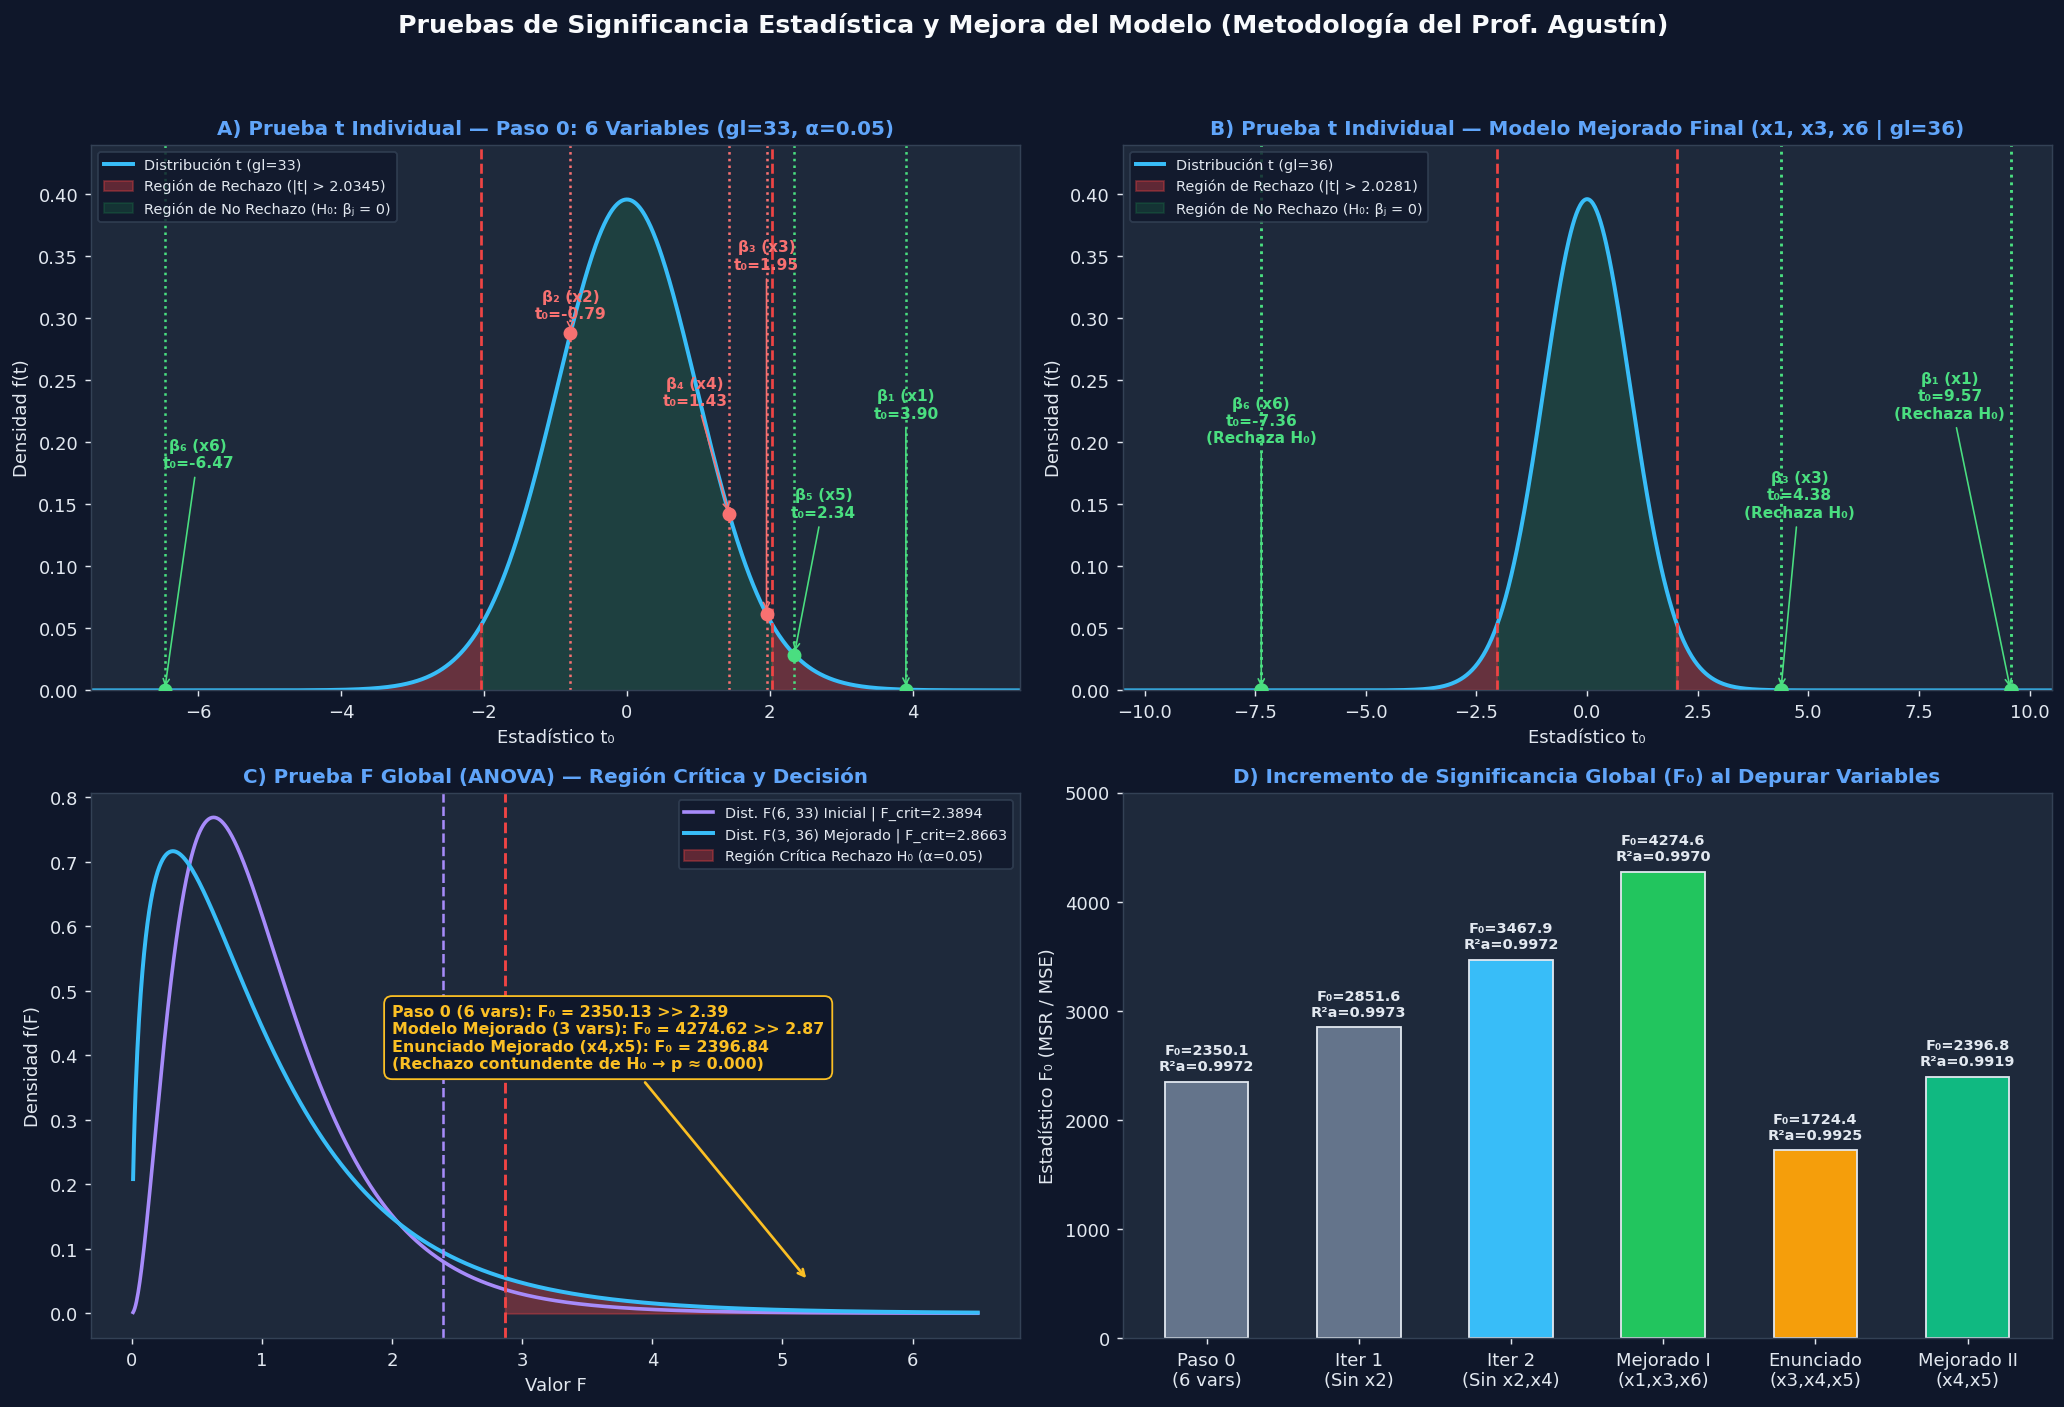

In [9]:
# Visualización de las Regiones Críticas de Significancia (t-Student y F Global)
plt.rcParams['figure.dpi'] = 130
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.patch.set_facecolor('#0f172a')

for ax in axes.flat:
    ax.set_facecolor('#1e293b')
    ax.tick_params(colors='#e2e8f0')
    ax.xaxis.label.set_color('#e2e8f0')
    ax.yaxis.label.set_color('#e2e8f0')
    ax.title.set_color('#60a5fa')
    for spine in ax.spines.values():
        spine.set_color('#334155')

# ------------------------------------------------------------------------------
# Panel A: Prueba t Individual — Modelo Inicial Completo de 6 Variables (gl = 33)
# ------------------------------------------------------------------------------
ax1 = axes[0, 0]
df1 = res_paso0['df_res']
t_crit1 = res_paso0['t_crit']
x_t = np.linspace(-7.5, 5.5, 1000)
y_t1 = stats.t.pdf(x_t, df1)

ax1.plot(x_t, y_t1, color='#38bdf8', lw=2.2, label=f'Distribución t (gl={df1})')
ax1.fill_between(x_t, 0, y_t1, where=(x_t <= -t_crit1) | (x_t >= t_crit1), color='#ef4444', alpha=0.35, label=f'Región de Rechazo (|t| > {t_crit1:.4f})')
ax1.fill_between(x_t, 0, y_t1, where=(x_t > -t_crit1) & (x_t < t_crit1), color='#22c55e', alpha=0.15, label='Región de No Rechazo (H₀: βⱼ = 0)')
ax1.axvline(-t_crit1, color='#ef4444', linestyle='--', lw=1.5)
ax1.axvline(t_crit1, color='#ef4444', linestyle='--', lw=1.5)

# Graficar únicamente los regresores (j = 1..6) con posiciones limpias sin solapamiento
offsets_p0 = {
    'x1': (3.904, 0.22),
    'x2': (-0.789, 0.30),
    'x3': (1.954, 0.34),
    'x4': (0.95, 0.23),
    'x5': (2.75, 0.14),
    'x6': (-6.0, 0.18)
}
for _, row in res_paso0['coef_df'].iloc[1:].iterrows():
    var_name = row['Variable']
    tv = row['t₀']
    col = '#4ade80' if row['¿Contribuye?'] == 'Sí' else '#f87171'
    ax1.axvline(tv, color=col, linestyle=':', lw=1.4)
    ax1.scatter([tv], [stats.t.pdf(tv, df1)], color=col, zorder=5, s=45)
    tx, ty = offsets_p0[var_name]
    ax1.annotate(f"{row['Coef.']}\nt₀={tv:.2f}", xy=(tv, stats.t.pdf(tv, df1)), xytext=(tx, ty),
                 color=col, fontsize=8.5, fontweight='bold', ha='center',
                 arrowprops=dict(arrowstyle='->', color=col, lw=0.9))

ax1.set_title('A) Prueba t Individual — Paso 0: 6 Variables (gl=33, α=0.05)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Estadístico t₀')
ax1.set_ylabel('Densidad f(t)')
ax1.set_xlim(-7.5, 5.5)
ax1.set_ylim(0, 0.44)
ax1.legend(loc='upper left', facecolor='#0f172a', edgecolor='#334155', labelcolor='#e2e8f0', fontsize=8)

# ------------------------------------------------------------------------------
# Panel B: Prueba t Individual — Modelo Mejorado Final (x1, x3, x6 | gl = 36)
# ------------------------------------------------------------------------------
ax2 = axes[0, 1]
df2 = res_mejorado['df_res']
t_crit2 = res_mejorado['t_crit']
x_t2 = np.linspace(-10.5, 10.5, 1000)
y_t2 = stats.t.pdf(x_t2, df2)

ax2.plot(x_t2, y_t2, color='#38bdf8', lw=2.2, label=f'Distribución t (gl={df2})')
ax2.fill_between(x_t2, 0, y_t2, where=(x_t2 <= -t_crit2) | (x_t2 >= t_crit2), color='#ef4444', alpha=0.35, label=f'Región de Rechazo (|t| > {t_crit2:.4f})')
ax2.fill_between(x_t2, 0, y_t2, where=(x_t2 > -t_crit2) & (x_t2 < t_crit2), color='#22c55e', alpha=0.15, label='Región de No Rechazo (H₀: βⱼ = 0)')
ax2.axvline(-t_crit2, color='#ef4444', linestyle='--', lw=1.5)
ax2.axvline(t_crit2, color='#ef4444', linestyle='--', lw=1.5)

offsets_opt = {
    'x1': (8.2, 0.22),
    'x3': (4.8, 0.14),
    'x6': (-7.365, 0.20)
}
for _, row in res_mejorado['coef_df'].iloc[1:].iterrows():
    var_name = row['Variable']
    tv = row['t₀']
    col = '#4ade80'
    ax2.axvline(tv, color=col, linestyle=':', lw=1.6)
    ax2.scatter([tv], [stats.t.pdf(tv, df2)], color=col, zorder=5, s=50)
    tx, ty = offsets_opt[var_name]
    ax2.annotate(f"{row['Coef.']}\nt₀={tv:.2f}\n(Rechaza H₀)", xy=(tv, stats.t.pdf(tv, df2)), xytext=(tx, ty),
                 color=col, fontsize=8.5, fontweight='bold', ha='center',
                 arrowprops=dict(arrowstyle='->', color=col, lw=0.9))

ax2.set_title('B) Prueba t Individual — Modelo Mejorado Final (x1, x3, x6 | gl=36)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Estadístico t₀')
ax2.set_ylabel('Densidad f(t)')
ax2.set_xlim(-10.5, 10.5)
ax2.set_ylim(0, 0.44)
ax2.legend(loc='upper left', facecolor='#0f172a', edgecolor='#334155', labelcolor='#e2e8f0', fontsize=8)

# ------------------------------------------------------------------------------
# Panel C: Prueba F Global (ANOVA)
# ------------------------------------------------------------------------------
ax3 = axes[1, 0]
x_f = np.linspace(0.01, 6.5, 1000)
y_f1 = stats.f.pdf(x_f, 6, 33)
y_f2 = stats.f.pdf(x_f, 3, 36)
f_crit1 = res_paso0['F_crit']
f_crit2 = res_mejorado['F_crit']

ax3.plot(x_f, y_f1, color='#a78bfa', lw=2, label=f'Dist. F(6, 33) Inicial | F_crit={f_crit1:.4f}')
ax3.plot(x_f, y_f2, color='#38bdf8', lw=2.2, label=f'Dist. F(3, 36) Mejorado | F_crit={f_crit2:.4f}')
ax3.fill_between(x_f, 0, y_f2, where=(x_f >= f_crit2), color='#ef4444', alpha=0.35, label='Región Crítica Rechazo H₀ (α=0.05)')
ax3.axvline(f_crit1, color='#a78bfa', linestyle='--', lw=1.4)
ax3.axvline(f_crit2, color='#ef4444', linestyle='--', lw=1.6)

ax3.annotate(f"Paso 0 (6 vars): F₀ = {res_paso0['F0']:.2f} >> {f_crit1:.2f}\nModelo Mejorado (3 vars): F₀ = {res_mejorado['F0']:.2f} >> {f_crit2:.2f}\nEnunciado Mejorado (x4,x5): F₀ = {res_proy_mej['F0']:.2f}\n(Rechazo contundente de H₀ → p ≈ 0.000)",
             xy=(5.2, 0.05), xytext=(2.0, 0.38),
             color='#fbbf24', fontsize=8.8, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#0f172a', edgecolor='#fbbf24'),
             arrowprops=dict(arrowstyle='->', color='#fbbf24', lw=1.5))

ax3.set_title('C) Prueba F Global (ANOVA) — Región Crítica y Decisión', fontsize=11, fontweight='bold')
ax3.set_xlabel('Valor F')
ax3.set_ylabel('Densidad f(F)')
ax3.legend(loc='upper right', facecolor='#0f172a', edgecolor='#334155', labelcolor='#e2e8f0', fontsize=8)

# ------------------------------------------------------------------------------
# Panel D: Evolución del Estadístico F0 en Backward Elimination
# ------------------------------------------------------------------------------
ax4 = axes[1, 1]
etapas = ['Paso 0\n(6 vars)', 'Iter 1\n(Sin x2)', 'Iter 2\n(Sin x2,x4)', 'Mejorado I\n(x1,x3,x6)', 'Enunciado\n(x3,x4,x5)', 'Mejorado II\n(x4,x5)']
f0_evol = [res_paso0['F0'], res_paso1['F0'], res_paso2['F0'], res_mejorado['F0'], res_proy_ini['F0'], res_proy_mej['F0']]
r2_evol = [res_paso0['R2_adj'], res_paso1['R2_adj'], res_paso2['R2_adj'], res_mejorado['R2_adj'], res_proy_ini['R2_adj'], res_proy_mej['R2_adj']]
bar_cols = ['#64748b', '#64748b', '#38bdf8', '#22c55e', '#f59e0b', '#10b981']

bars = ax4.bar(etapas, f0_evol, color=bar_cols, width=0.55, edgecolor='#e2e8f0')
for bar, fval, r2a in zip(bars, f0_evol, r2_evol):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 75,
             f'F₀={fval:.1f}\nR²a={r2a:.4f}',
             ha='center', va='bottom', color='#e2e8f0', fontsize=8, fontweight='bold')

ax4.set_title('D) Incremento de Significancia Global (F₀) al Depurar Variables', fontsize=11, fontweight='bold')
ax4.set_ylabel('Estadístico F₀ (MSR / MSE)')
ax4.set_ylim(0, 5000)

plt.suptitle('Pruebas de Significancia Estadística y Mejora del Modelo (Metodología del Prof. Agustín)', color='#f8fafc', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()